# 02 Experiment checks (finding 1)

Before trusting any lift number, check that the randomisation worked. Three checks: the treated share, balance on the features, and whether a model can tell the groups apart. Write-up: `docs/experiment_health.md`.

In [1]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from incrementality.style import PAL, SOURCE, SOURCE_IOWA, apply, finish

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRITEO = (ROOT / "data" / "processed" / "criteo_uplift.parquet").as_posix()
results = lambda name: json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))
show = lambda name: display(Image(filename=str(ROOT / "figures" / name), width=900))
pd.set_option("display.float_format", "{:,.4f}".format)
apply()

In [2]:
from incrementality.experiment import FEATURES, balance, classifier_test, srm

con = duckdb.connect()
n_total, n_treated = con.execute(f"SELECT count(*), sum(treatment) FROM '{CRITEO}'").fetchone()
r = srm(int(n_treated), int(n_total), 0.85)
print(f"Treated share {r.observed_share:.5f} vs designed 0.85: chi-square p = {r.p_value:.3f}, mismatch: {r.mismatch}")

Treated share 0.85000 vs designed 0.85: chi-square p = 0.999, mismatch: False


The split is exactly as designed. (So exactly that Criteo probably fixed it when building the file, so this check confirms the file is complete rather than proving the original tests were clean.)

**Balance:** standardised mean difference (SMD) is the gap between group averages in units of the feature's spread. Under 0.1 is the usual "balanced" line.

In [3]:
bal = balance(con, f"'{CRITEO}'")
bal

,feature,mean_treated,mean_control,sd_pooled,smd
0,f0,19.6148,19.6517,5.3818,-0.0069
1,f1,10.0703,10.0679,0.1001,0.0240
2,f2,8.4463,8.4482,0.2999,-0.0062
3,f3,4.1694,4.2328,1.2984,-0.0488
4,f4,10.3392,10.3365,0.3414,0.0080
5,f5,4.0266,4.0393,0.4168,-0.0306
6,f6,-4.1828,-3.9999,4.5222,-0.0404
7,f7,5.1056,5.0803,1.1881,0.0213
8,f8,3.9334,3.9347,0.0562,-0.0224
9,f9,16.0526,15.8863,6.9304,0.0240


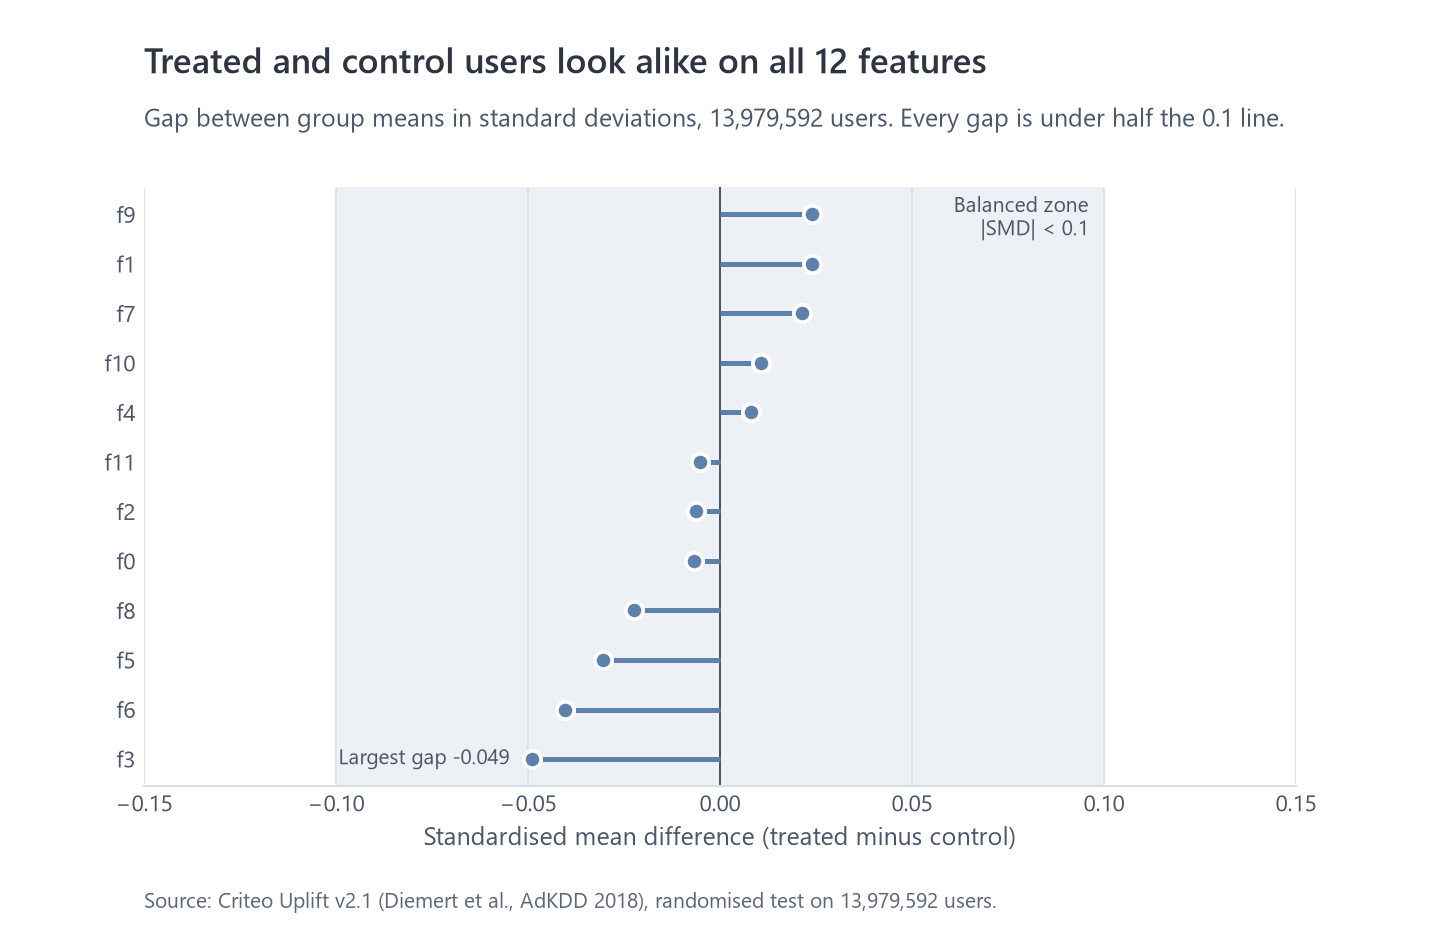

In [4]:
show("experiment/balance.png")

Every gap is under 0.05. But with 14 million users, chance alone moves an SMD by only about 0.00075, so these small gaps are real.

**Classifier test:** if assignment were random, no model could predict it from the features (AUC 0.5). The full check on 1 million users is in `results/experiment_checks.json`; here is a quicker live version on 200,000 users, plus a placebo with shuffled labels.

In [5]:
sample = duckdb.sql(f"SELECT {', '.join(FEATURES)}, treatment FROM '{CRITEO}' USING SAMPLE 200000 ROWS (reservoir, 7)").df()
live = classifier_test(sample[FEATURES], sample["treatment"], folds=3, seed=7)
shuffled = sample["treatment"].sample(frac=1, random_state=8).reset_index(drop=True)
placebo = classifier_test(sample[FEATURES], shuffled, folds=3, seed=7)
full = results("experiment_checks")
pd.DataFrame({
    "AUC": [live.auc, placebo.auc, full["classifier"]["auc"], full["classifier_placebo"]["auc"]],
    "standard errors from 0.5": [live.z, placebo.z, full["classifier"]["z"], full["classifier_placebo"]["z"]],
}, index=["live, 200k users", "live placebo", "full, 1M users", "full placebo"])

,AUC,standard errors from 0.5
"live, 200k users",0.5076,4.1799
live placebo,0.4993,-0.3897
"full, 1M users",0.5088,10.9264
full placebo,0.4990,-1.2094


A model beats a coin flip by a hair, and the placebo shows that edge is real. Criteo's paper explains why: the file merges several advertisers' tests that had different treated shares. The features were logged before any ad was shown, so notebook 03 adjusts for them.